# Reconstruction

The Reconstruction class allows for the reconstruction of population properties based on a reference sample.\
For instance, it can be used as an alternative to self-organizing maps to estimate the $n(z)$ of a tomographically selected photometric sample.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fomoz.data import Dataset
from fomoz.probability import Reconstruction

## Input samples

For demonstration purposes, we use the same catalog as both the reference and test samples. This illustrates the workflow, not performance on an independent sample. In realistic scenarios, reference and test samples must be independent.

Magnitude errors must be present in the input catalogs, because they define the matching between reference and test objects. Here, we assume 0.1 mag errors.

In [2]:
# Load the sample and assign dummy magnitude errors
sample = pd.read_csv('../data/input/reference.csv', comment='#')
bands = ['g', 'r', 'i']

for band in bands:
    if f'{band}_error' not in sample:
        sample[f'{band}_error'] = 0.1
        print(f'{band}: assuming 0.1 mag uncertainty for this example.')

# Nearly identical samples, for demonstration only.
# The Reconstruction class raises an error if reference and test samples are identical.
# Here, we omit the last row from the test sample as a workaround.
ref_sample = sample.copy()
test_sample = sample.iloc[:-1].copy()
reference = Dataset(ref_sample, bands, z_gal_string='redshift')
test = Dataset(test_sample.drop(columns='redshift'), bands, z_gal_string=None)

g: assuming 0.1 mag uncertainty for this example.
r: assuming 0.1 mag uncertainty for this example.
i: assuming 0.1 mag uncertainty for this example.


## Reconstruct a selected population
Select objects between the reference i-band magnitude quartiles and reconstruct their redshift distribution. The full reference sample is used for feature selection.


In [3]:
i_min, i_max = ref_sample['i'].quantile([0.25, 0.75])

reconstruction = Reconstruction(
    reference_dataset=reference,
    test_dataset=test,
    selection_variable='i',
    selection_min=i_min,
    selection_max=i_max,
)
reconstruction.select_features_grid()
reconstruction.process(cpu_number=1)

bin_edges = np.linspace(0, sample['redshift'].max() + 0.01, 31)
nz = reconstruction.get_distribution('redshift', bin_edges, normalize=True)

Reconstruction selection: 23.23508874049027 < i <= 24.57444084803525. Reference: 2614/5230; test: 2614/5229.
Feature selection uses the full reference. Matching uses selected subsets.

GridClassification processing complete. Employed time: 0.06 s.

GridClassification's purity and completeness (respectively): 0.88, 0.02
Purity and completeness after the selection of features : 0.88, 0.02
Feature selection complete after 0 iterations. Employed time: 0.00 s.


/home/giorgio/.local/lib/python3.8/site-packages/fomoz/probability/point_probability.py:684: UserWarning: No feature could be removed within tolerance. Using all available features.
  warnings.warn(
Reconstructing reference contributions: 100%|██████████| 2614/2614 [00:00<00:00, 13712.00it/s]

Matching complete.
Reconstructing 'redshift' using reference point estimates.


Compare with the catalog redshifts of all selected test galaxies.

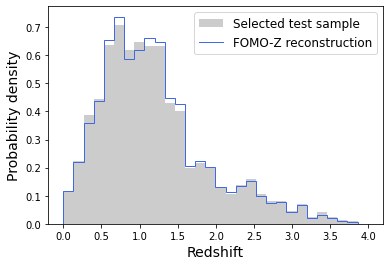

In [10]:
selected = (test_sample['i'] > i_min) & (test_sample['i'] <= i_max)

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(test_sample.loc[selected, 'redshift'], bins=bin_edges, density=True, color='gray', alpha=0.4, label='Selected test sample')
ax.stairs(nz, bin_edges, color='royalblue', label='FOMO-Z reconstruction')
ax.set_xlabel('Redshift', fontsize=14)
ax.set_ylabel('Probability density', fontsize=14)
ax.legend(fontsize=12)
plt.show()